In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,  OneHotEncoder, OrdinalEncoder, LabelEncoder
from imblearn.over_sampling import SMOTE

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
filepath = '/content/drive/MyDrive/Ict_files/adult_dataset.csv'
df = pd.read_csv(filepath)

## EDA

In [11]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [13]:
df.shape

(48842, 15)

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,46400.0,38.679116,13.952954,17.0,28.0,37.0,48.0,255.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,46400.0,40.448599,12.646992,1.0,40.0,40.0,45.0,250.0


In [15]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

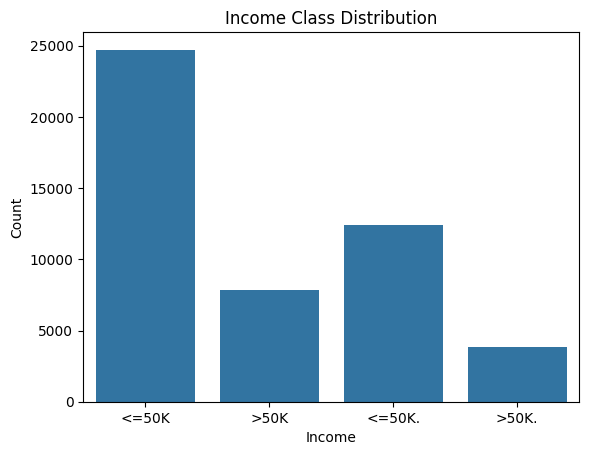

In [16]:
sns.countplot(data=df, x='income')
plt.title('Income Class Distribution')
plt.xlabel('Income')
plt.ylabel('Count')
plt.show()

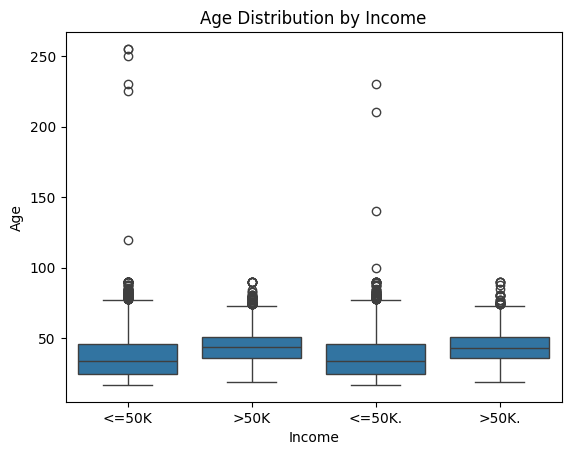

In [17]:
sns.boxplot(data=df, x='income', y='age')
plt.title('Age Distribution by Income')
plt.xlabel('Income')
plt.ylabel('Age')
plt.show()

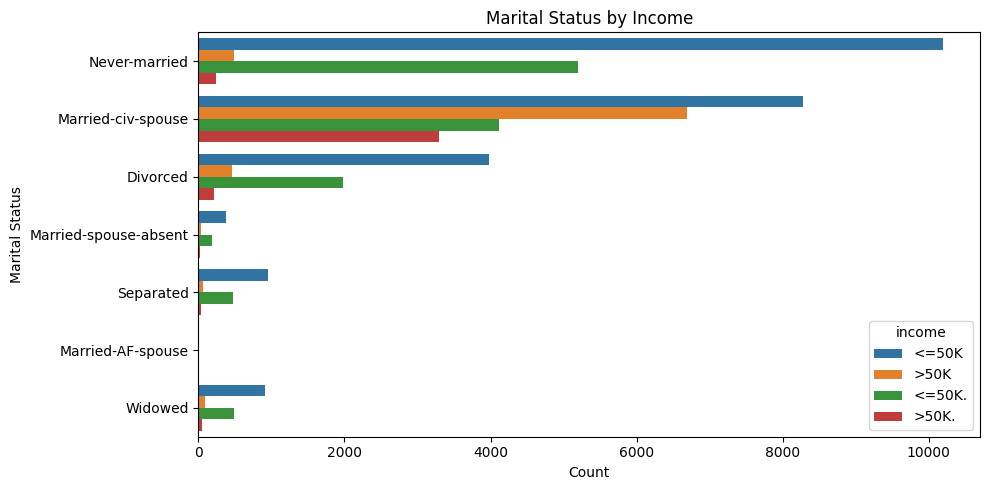

In [18]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='marital-status', hue='income')
plt.title('Marital Status by Income')
plt.xlabel('Count')
plt.ylabel('Marital Status')
plt.tight_layout()
plt.show()

## Data Cleaning


In [19]:
df['income'].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [20]:
df['income'] = df['income'].str.replace('.','')

### Replacing '?' with NaN

In [21]:
df = df.replace("?", np.nan)

In [22]:
df['income'].unique()

array(['<=50K', '>50K'], dtype=object)

### Checking Missing Values

In [23]:
df.isna().sum()

,0
age,2442
workclass,5125
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,5115
relationship,0
race,0
sex,0


In [24]:
(df.isna().sum())/len(df)*100

,0
age,4.999795
workclass,10.493018
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,10.472544
relationship,0.000000
race,0.000000
sex,0.000000


### Distribution of Numerical Features

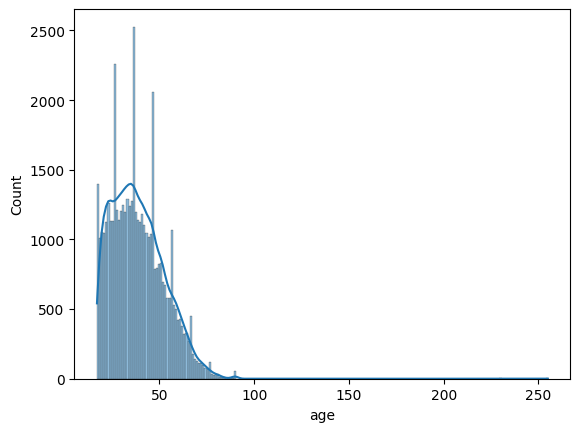

In [25]:
sns.histplot(data=df,x='age',kde=True)
plt.show()

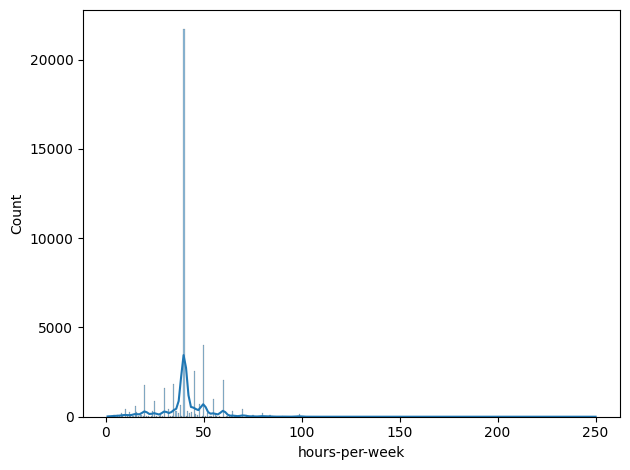

In [26]:
sns.histplot(data=df,x='hours-per-week',kde=True)
plt.tight_layout()
plt.show()

### Handling Duplicate Rows

In [27]:
df.duplicated().sum()

np.int64(29)

In [28]:
df=df.drop_duplicates()

In [29]:
df.duplicated().sum()

np.int64(0)

## Separating Features and Target

In [30]:
y=df['income']
X = df.drop('income',axis=1)

### Checking Class Imbalance

In [31]:
y.value_counts()

,count
income,
<=50K,37127
>50K,11686


## Train-Test Split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [33]:
X_test

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
20885,18.0,Private,240183,HS-grad,9,Never-married,Other-service,Own-child,White,Female,0,0,20.0,United-States
29249,32.0,Private,206541,Assoc-voc,11,Married-civ-spouse,Tech-support,Husband,White,Male,0,0,45.0,United-States
28922,57.0,NaN,85815,HS-grad,9,Divorced,NaN,Own-child,Asian-Pac-Islander,Male,0,0,20.0,NaN
2213,60.0,NaN,131852,5th-6th,3,Married-civ-spouse,NaN,Husband,White,Male,0,0,30.0,United-States
27117,46.0,Private,54190,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,60.0,United-States
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253,19.0,Local-gov,27382,Some-college,10,Never-married,Adm-clerical,Own-child,White,Male,0,0,40.0,United-States
286,41.0,Private,220531,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60.0,United-States
21881,30.0,Federal-gov,43953,Assoc-acdm,12,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,40.0,United-States
11388,23.0,Private,82393,9th,5,Never-married,Other-service,Own-child,Asian-Pac-Islander,Male,0,0,20.0,Philippines





## Numerical and Categorical Columns

In [34]:
num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(exclude='number').columns

In [35]:
for cols in cat_cols:
  print(f"{cols}==>{df[cols].unique()}\n")

workclass==>['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' nan 'Local-gov'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

education==>['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']

marital-status==>['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']

occupation==>['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' nan
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']

relationship==>['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']

race==>['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']

sex==>['Male' 'Female']

native-country==>[nan 'United-States' 'Cuba' 'Jamaica' 'India' 'Mexico' 'South'
 'Puerto-Rico' 'Hondur

In [36]:
num_cols

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [37]:
cat_cols

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

## Missing value handling for numerical features

In [38]:
imputer_num = SimpleImputer(strategy='median')
X_train_num = imputer_num.fit_transform(X_train[num_cols])
X_test_num = imputer_num.transform(X_test[num_cols])

## Scaling

In [39]:
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

In [40]:
X_train_num_scaled = pd.DataFrame(
    X_train_num_scaled,
    columns=num_cols,
    index=X_train.index
)

X_test_num_scaled = pd.DataFrame(
    X_test_num_scaled,
    columns=num_cols,
    index=X_test.index
)

## Missing value handling for categorical features

In [41]:
for cols in cat_cols:
  print(f"{cols}==>{X_train[cols].unique()}\n")

workclass==>[nan 'Private' 'State-gov' 'Self-emp-inc' 'Self-emp-not-inc' 'Local-gov'
 'Federal-gov' 'Never-worked' 'Without-pay']

education==>['Bachelors' 'HS-grad' 'Prof-school' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '10th' 'Masters' '7th-8th' '11th' '9th' 'Doctorate' '5th-6th'
 '1st-4th' '12th' 'Preschool']

marital-status==>['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-AF-spouse'
 'Widowed' 'Separated' 'Married-spouse-absent']

occupation==>[nan 'Prof-specialty' 'Adm-clerical' 'Sales' 'Exec-managerial'
 'Other-service' 'Handlers-cleaners' 'Machine-op-inspct' 'Craft-repair'
 'Farming-fishing' 'Tech-support' 'Transport-moving' 'Protective-serv'
 'Priv-house-serv' 'Armed-Forces']

relationship==>['Own-child' 'Husband' 'Not-in-family' 'Unmarried' 'Wife' 'Other-relative']

race==>['White' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Black' 'Other']

sex==>['Male' 'Female']

native-country==>['United-States' nan 'Cuba' 'Mexico' 'Ireland' 'Philippines' 'Poland'
 'Ecuador' 'Can

In [42]:
print(X_train[cat_cols].isna().sum())
print('\n')
print(X_test[cat_cols].isna().sum())

workclass         4073
education            0
marital-status       0
occupation        4104
relationship         0
race                 0
sex                  0
native-country    2596
dtype: int64


workclass         1048
education            0
marital-status       0
occupation        1007
relationship         0
race                 0
sex                  0
native-country     664
dtype: int64


In [43]:
imputer_cat = SimpleImputer(strategy='most_frequent')
X_train_cat = imputer_cat.fit_transform(X_train[cat_cols])
X_test_cat = imputer_cat.transform(X_test[cat_cols])

## One-Hot Encoding of Categorical Features

In [44]:
encoder = OneHotEncoder(handle_unknown='ignore')
X_train_cat_encoded = encoder.fit_transform(X_train_cat)
X_test_cat_encoded = encoder.transform(X_test_cat)

### Converting Encoded Output to DataFrames

In [45]:
X_train_cat_encoded = pd.DataFrame(
    X_train_cat_encoded.toarray(),
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_train.index
)

X_test_cat_encoded = pd.DataFrame(
    X_test_cat_encoded.toarray(),
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_test.index
)

In [46]:
X_train_cat_encoded.head()

,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_10th,education_11th,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
33441,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
39981,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
47829,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
46480,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
30890,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## Combining Numerical and Categorical Features

In [47]:
X_train_final = pd.concat([X_train_num_scaled, X_train_cat_encoded], axis = 1)
X_test_final = pd.concat([X_test_num_scaled, X_test_cat_encoded], axis = 1)

In [48]:
print(X_train_final.shape)
print(X_test_final.shape)


(39050, 105)
(9763, 105)


## Label Encoding the Target

In [49]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)
print(pd.Series(y_train_encoded).value_counts())
print(pd.Series(y_test_encoded).value_counts()) #check imbalance

['<=50K' '>50K']
0    29701
1     9349
Name: count, dtype: int64
0    7426
1    2337
Name: count, dtype: int64


## Handling Class Imbalance using SMOTE

In [50]:
smote = SMOTE(random_state=42)
X_train_resampled , y_train_resampled = smote.fit_resample(X_train_final, y_train_encoded)

print("Before SMOTE:", pd.Series(y_train_encoded).value_counts().to_dict())
print("After SMOTE:", pd.Series(y_train_resampled).value_counts().to_dict())
print(X_train_final.shape, "->", X_train_resampled.shape)

Before SMOTE: {0: 29701, 1: 9349}
After SMOTE: {0: 29701, 1: 29701}
(39050, 105) -> (59402, 105)


## Feature Selection
### Correlation of Features with the Target

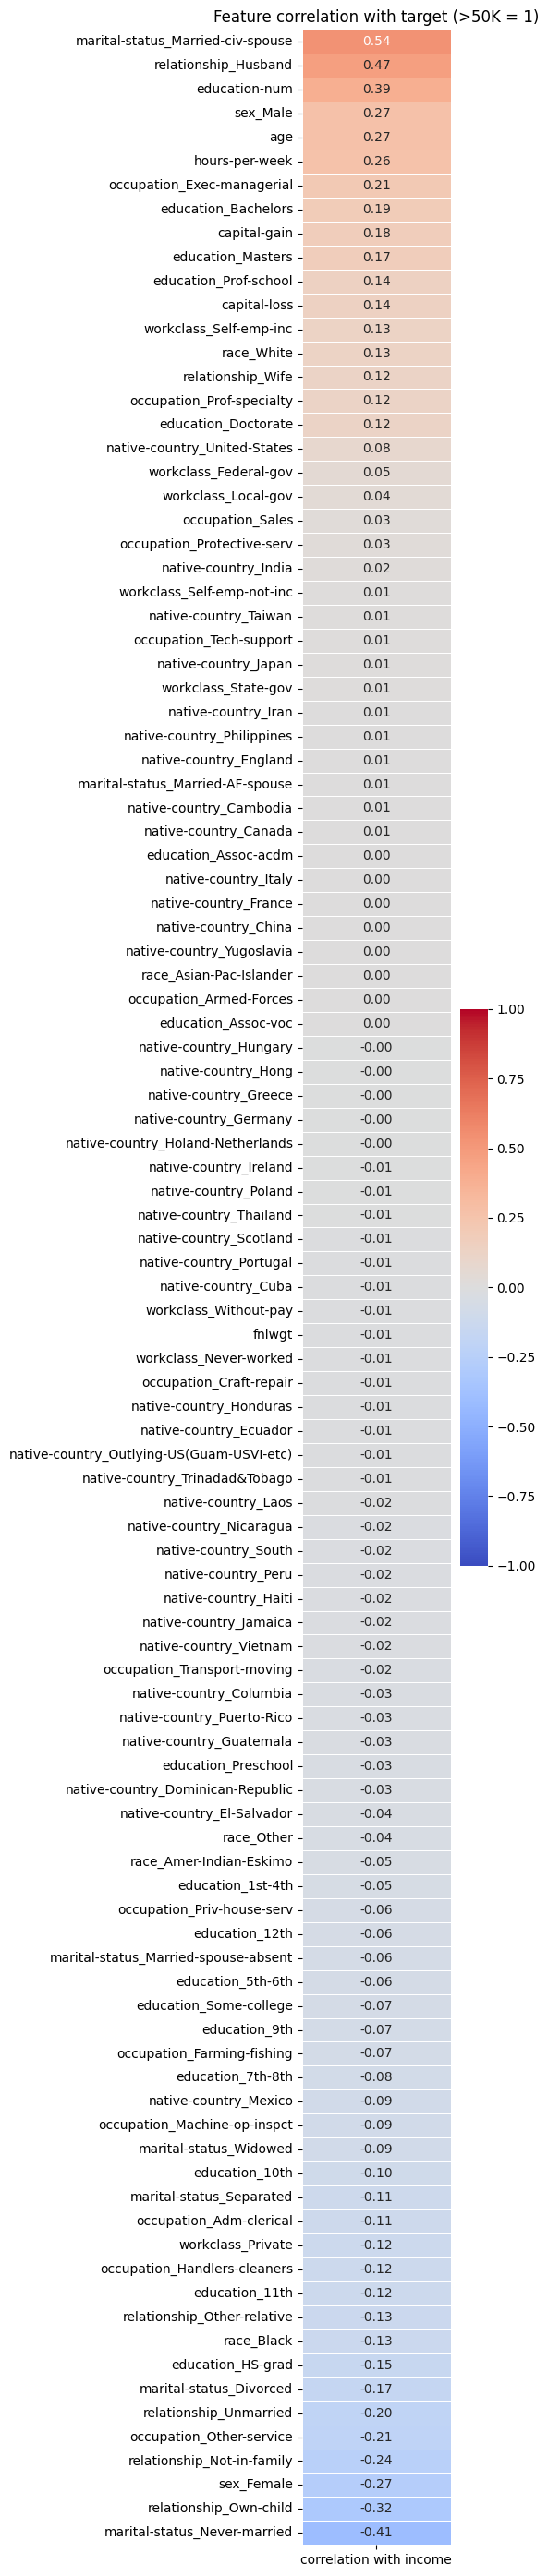

In [51]:
y_series = pd.Series(y_train_resampled, index=X_train_resampled.index)

corr_target = (
    X_train_resampled.corrwith(y_series)
    .sort_values(ascending=False)
    .to_frame(name="correlation with income")
)

plt.figure(figsize=(6, 28))
sns.heatmap(
    corr_target,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Feature correlation with target (>50K = 1)")
plt.tight_layout()
plt.show()

### Features Selection

In [52]:
features_selected = [
    'marital-status_Married-civ-spouse',
    'relationship_Husband',
    'education-num',
    'marital-status_Never-married',
    'relationship_Own-child'
]

X_train_selected = X_train_resampled[features_selected]
X_test_selected = X_test_final[features_selected]

In [53]:
print(X_train_selected)
print('\n')
print(X_test_selected)

       marital-status_Married-civ-spouse  relationship_Husband  education-num  \
0                                    0.0              0.000000       1.133555   
1                                    1.0              1.000000      -0.420269   
2                                    0.0              0.000000       1.910467   
3                                    0.0              0.000000       1.133555   
4                                    1.0              1.000000       1.133555   
...                                  ...                   ...            ...   
59397                                1.0              1.000000       1.522011   
59398                                1.0              1.000000       1.522011   
59399                                1.0              1.000000      -0.031813   
59400                                1.0              0.379926       2.298923   
59401                                1.0              1.000000       0.260732   

       marital-status_Never